# Zomato Restaurant Reviews — EDA & NLP Sentiment Prediction
**Project type:** EDA + NLP Classification | **Contribution:** Individual | **Author:** [Your Name]

## Project summary
This project analyses 10,000 Zomato restaurant review records and 105 restaurant metadata records. It explores customer ratings, review length, picture uploads, restaurant activity, cuisine and listed cost, then trains a text classifier for negative, neutral and positive rating-derived sentiment. After excluding records with unusable ratings or empty cleaned text, 9,936 reviews remain for supervised learning. The target is explicitly defined as ratings 1–2 = Negative, 3 = Neutral and 4–5 = Positive. These are proxy labels derived from ratings rather than independent human sentiment annotations.

The workflow includes data validation, missing-value and duplicate checks, conservative text cleaning, feature engineering, 18 meaningful visualizations, three statistical hypothesis tests and three machine-learning models. Text is converted to unigram/bigram TF-IDF features. Logistic Regression, Linear SVM and Multinomial Naive Bayes are tuned using stratified three-fold cross-validation and macro-F1. A stratified 80:20 hold-out set is reserved for final evaluation. The selected model is saved as a single Joblib pipeline and checked on unseen review text. The intended business use is to help prioritize feedback for human inspection, detect possible dissatisfaction patterns and support restaurant experience monitoring. Predictions are decision-support signals, not a replacement for human review or causal analysis.

**GitHub:** Add repository URL after upload.  
**Problem statement:** How can restaurant review text and related attributes be analysed to understand customer experience and classify reviews into rating-derived sentiment categories?

## 1. Know your data

In [1]:
import re, warnings, numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns, joblib
from scipy.stats import mannwhitneyu, chi2_contingency, kruskal
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer, CountVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report, confusion_matrix
warnings.filterwarnings("ignore")
REV_PATH = "Zomato Restaurant reviews.csv"
META_PATH = "Zomato Restaurant names and Metadata.csv"
reviews_raw = pd.read_csv(REV_PATH)
meta_raw = pd.read_csv(META_PATH)
print(reviews_raw.shape, meta_raw.shape)
display(reviews_raw.head(), meta_raw.head())

(10000, 7) (105, 6)


,Restaurant,Reviewer,Review,Rating,Metadata,Time,Pictures
0,Beyond Flavours,Rusha Chakraborty,"The ambience was good, food was quite good . h...",5,"1 Review , 2 Followers",5/25/2019 15:54,0
1,Beyond Flavours,Anusha Tirumalaneedi,Ambience is too good for a pleasant evening. S...,5,"3 Reviews , 2 Followers",5/25/2019 14:20,0
2,Beyond Flavours,Ashok Shekhawat,A must try.. great food great ambience. Thnx f...,5,"2 Reviews , 3 Followers",5/24/2019 22:54,0
3,Beyond Flavours,Swapnil Sarkar,Soumen das and Arun was a great guy. Only beca...,5,"1 Review , 1 Follower",5/24/2019 22:11,0
4,Beyond Flavours,Dileep,Food is good.we ordered Kodi drumsticks and ba...,5,"3 Reviews , 2 Followers",5/24/2019 21:37,0


,Name,Links,Cost,Collections,Cuisines,Timings
0,Beyond Flavours,https://www.zomato.com/hyderabad/beyond-flavou...,800,"Food Hygiene Rated Restaurants in Hyderabad, C...","Chinese, Continental, Kebab, European, South I...","12noon to 3:30pm, 6:30pm to 11:30pm (Mon-Sun)"
1,Paradise,https://www.zomato.com/hyderabad/paradise-gach...,800,Hyderabad's Hottest,"Biryani, North Indian, Chinese",11 AM to 11 PM
2,Flechazo,https://www.zomato.com/hyderabad/flechazo-gach...,"1,300","Great Buffets, Hyderabad's Hottest","Asian, Mediterranean, North Indian, Desserts","11:30 AM to 4:30 PM, 6:30 PM to 11 PM"
3,Shah Ghouse Hotel & Restaurant,https://www.zomato.com/hyderabad/shah-ghouse-h...,800,Late Night Restaurants,"Biryani, North Indian, Chinese, Seafood, Bever...",12 Noon to 2 AM
4,Over The Moon Brew Company,https://www.zomato.com/hyderabad/over-the-moon...,"1,200","Best Bars & Pubs, Food Hygiene Rated Restauran...","Asian, Continental, North Indian, Chinese, Med...","12noon to 11pm (Mon, Tue, Wed, Thu, Sun), 12no..."


### Dataset information, duplicates and missing values

In [2]:
reviews_raw.info()
display(reviews_raw.isna().sum().rename("missing_review_fields"))
display(meta_raw.isna().sum().rename("missing_metadata_fields"))
print("Duplicate review rows:", reviews_raw.duplicated().sum())
print("Review restaurants:", reviews_raw.Restaurant.nunique(), "| Metadata restaurants:", meta_raw.Name.nunique())
print("Rating values:", reviews_raw.Rating.value_counts(dropna=False))

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 7 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   Restaurant  10000 non-null  object
 1   Reviewer    9962 non-null   object
 2   Review      9955 non-null   object
 3   Rating      9962 non-null   object
 4   Metadata    9962 non-null   object
 5   Time        9962 non-null   object
 6   Pictures    10000 non-null  int64 
dtypes: int64(1), object(6)
memory usage: 547.0+ KB


Restaurant     0
Reviewer      38
Review        45
Rating        38
Metadata      38
Time          38
Pictures       0
Name: missing_review_fields, dtype: int64

Name            0
Links           0
Cost            0
Collections    54
Cuisines        0
Timings         1
Name: missing_metadata_fields, dtype: int64

Duplicate review rows: 36
Review restaurants: 100 | Metadata restaurants: 105
Rating values: Rating
5       3832
4       2373
1       1735
3       1193
2        684
4.5       69
3.5       47
NaN       38
2.5       19
1.5        9
Like       1
Name: count, dtype: int64


### What did you know about the dataset?
- Review file: 10,000 rows, 7 fields, 100 unique restaurants.
- Metadata file: 105 rows, 6 fields.
- Review text missing: 45; ratings missing: 38.
- The rating field is text and contains numeric values, missing values and a non-numeric `Like` entry.
- Model-ready data: 9,936 records; excluded from supervised learning: 64.

## 2. Variables and data wrangling

| Field | Description | Use |
|---|---|---|
| Restaurant | Restaurant name | Grouping / metadata join |
| Reviewer | Reviewer display name | Identifier; excluded from model |
| Review | Free text | NLP input |
| Rating | Source rating | Parsed numeric / proxy target |
| Metadata | Reviewer activity information | Descriptive |
| Time | Review timestamp | Parsed temporal feature |
| Pictures | Picture count | Numeric / binary presence |
| Cost, Cuisines, Collections, Timings | Restaurant metadata | Contextual analysis |

In [3]:
def clean_review(t):
    t=str(t).lower()
    t=re.sub(r"https?://\S+|www\.\S+"," ",t)
    t=re.sub(r"\b\w*\d\w*\b"," ",t)
    t=re.sub(r"[^a-z\s]"," ",t)
    return re.sub(r"\s+"," ",t).strip()
df=reviews_raw.copy()
df["Rating_num"]=pd.to_numeric(df.Rating,errors="coerce")
df["Review"]=df.Review.fillna("").astype(str)
df["review_clean"]=df.Review.map(clean_review)
df["Time_parsed"]=pd.to_datetime(df.Time,errors="coerce")
df["review_length"]=df.Review.str.len()
df["word_count"]=df.Review.str.split().str.len()
df["has_picture"]=(pd.to_numeric(df.Pictures,errors="coerce").fillna(0)>0).astype(int)
model_df=df.dropna(subset=["Rating_num"]).copy()
model_df=model_df[model_df.Rating_num.between(1,5)&(model_df.review_clean.str.len()>0)]
model_df["sentiment"]=pd.cut(model_df.Rating_num,[0,2,3,5.01],labels=["Negative","Neutral","Positive"],include_lowest=True).astype(str)
meta=meta_raw.copy()
meta["Cost_num"]=pd.to_numeric(meta.Cost.astype(str).str.replace(",","",regex=False),errors="coerce")
merged=df.merge(meta,left_on="Restaurant",right_on="Name",how="left")
print("Rows retained for supervised learning:",len(model_df))

Rows retained for supervised learning: 9936


### Manipulations and insights
Ratings are converted to numeric; missing/non-numeric target values are not imputed. Review text is preserved and cleaned in a separate field. Timestamps, word count, character length and picture presence are engineered. Restaurant metadata is joined by exact restaurant name. 9,936 records are retained for modelling; 64 are excluded because the target or usable text is unavailable.

## 3. Data visualization, storytelling and experimenting with charts — UBM

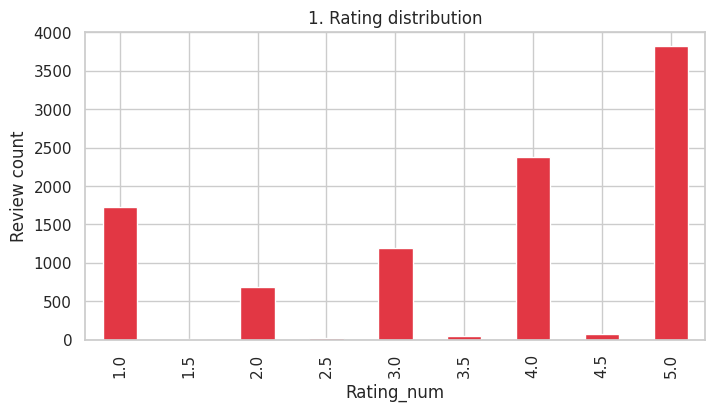

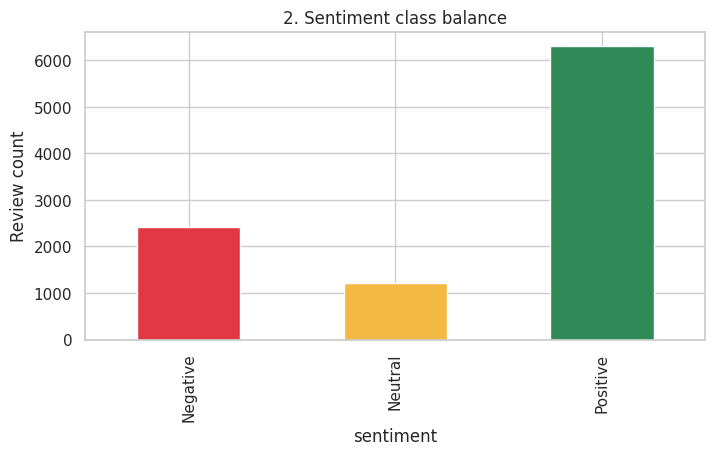

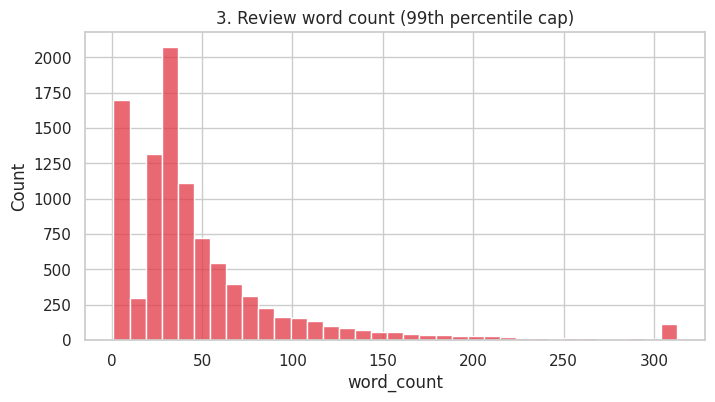

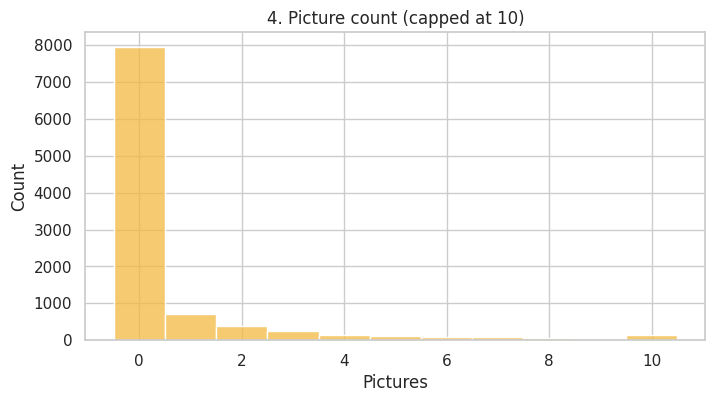

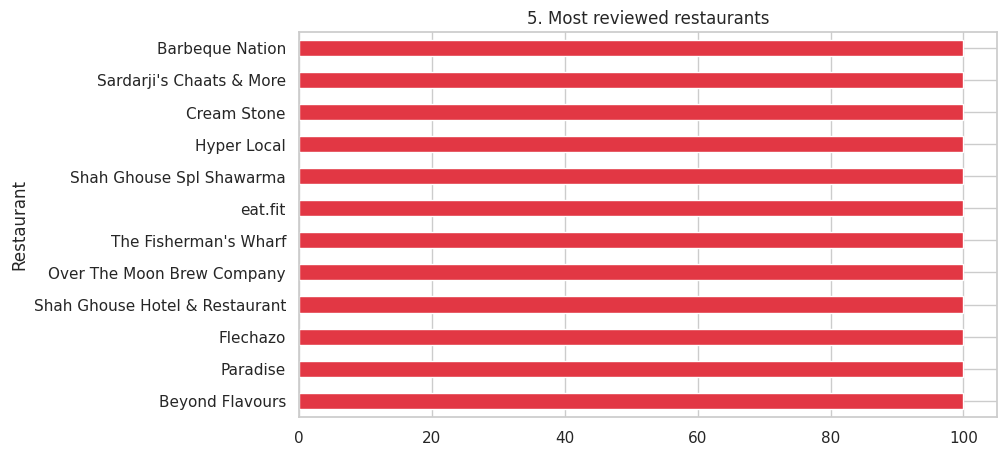

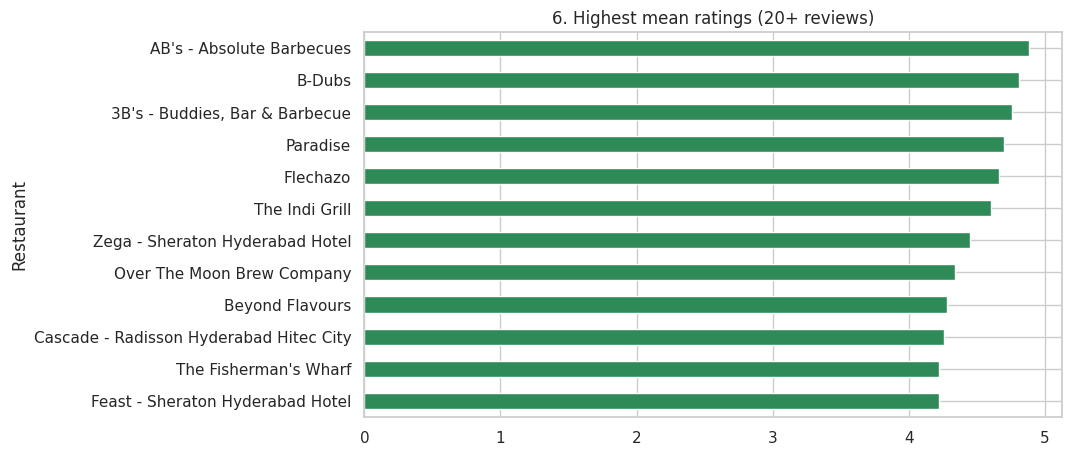

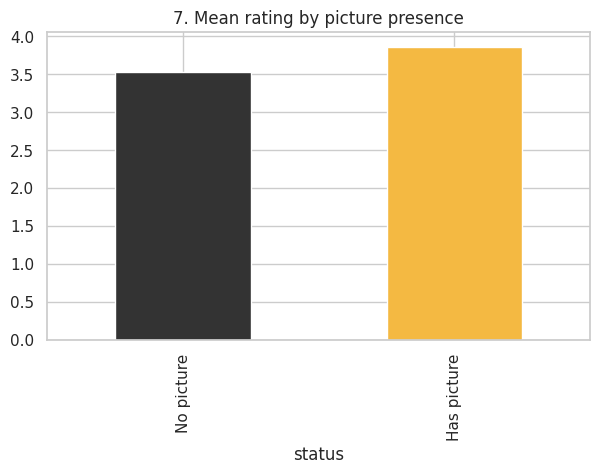

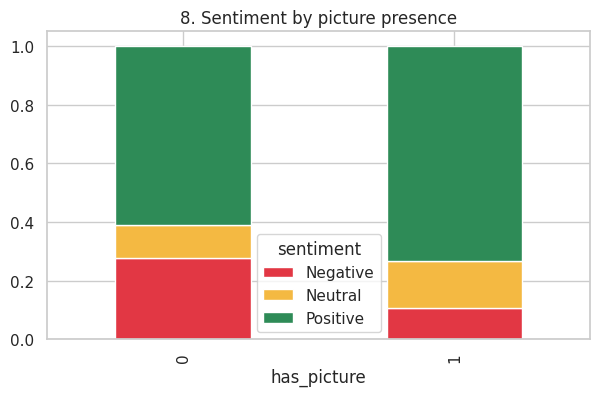

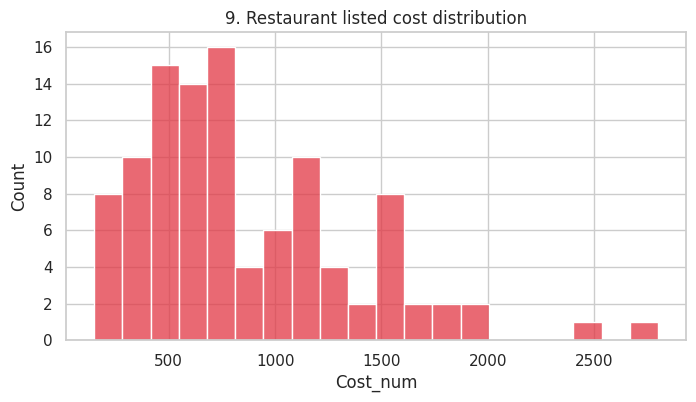

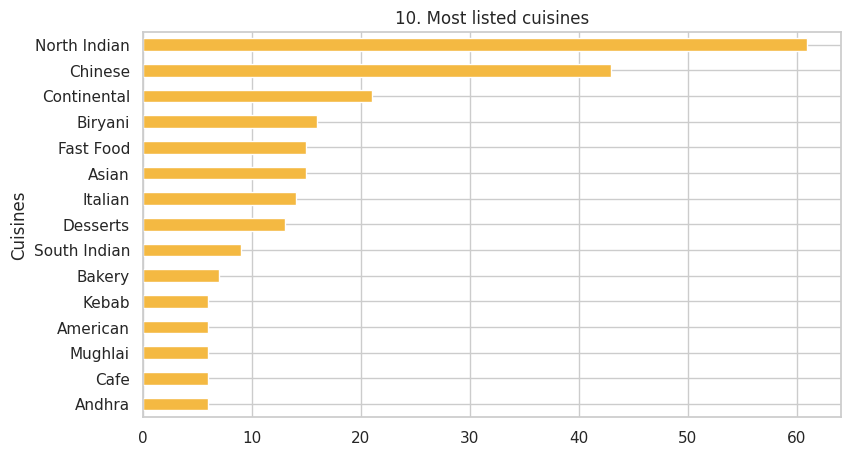

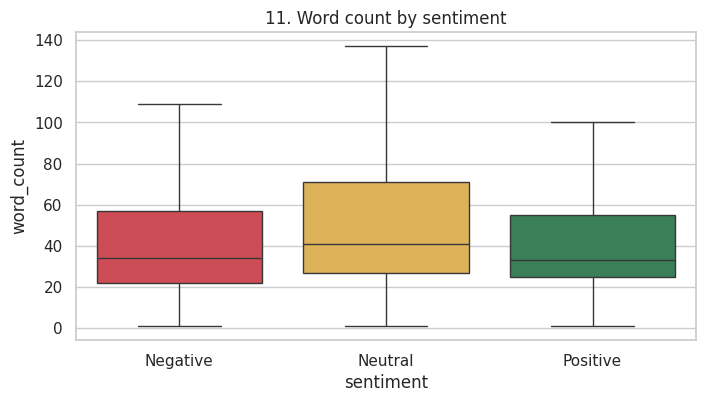

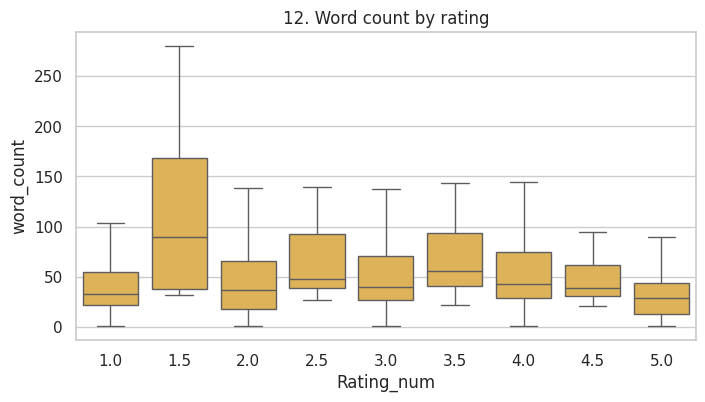

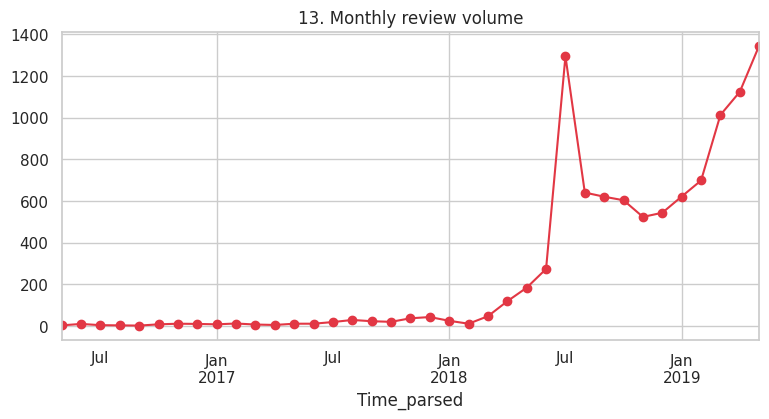

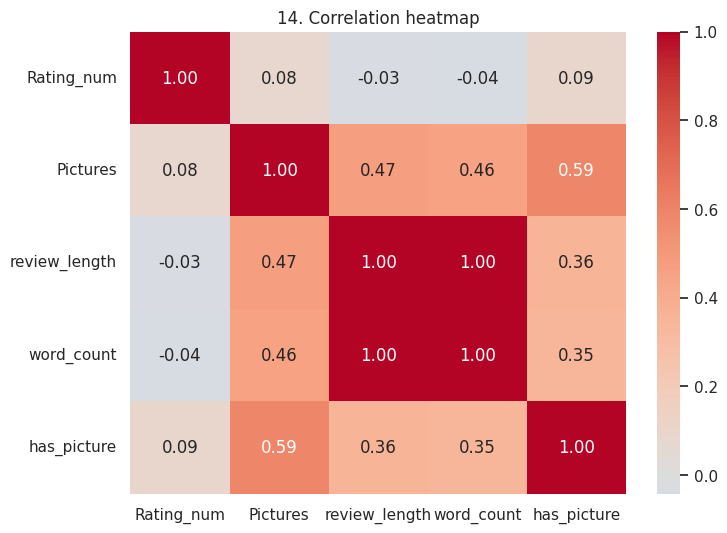

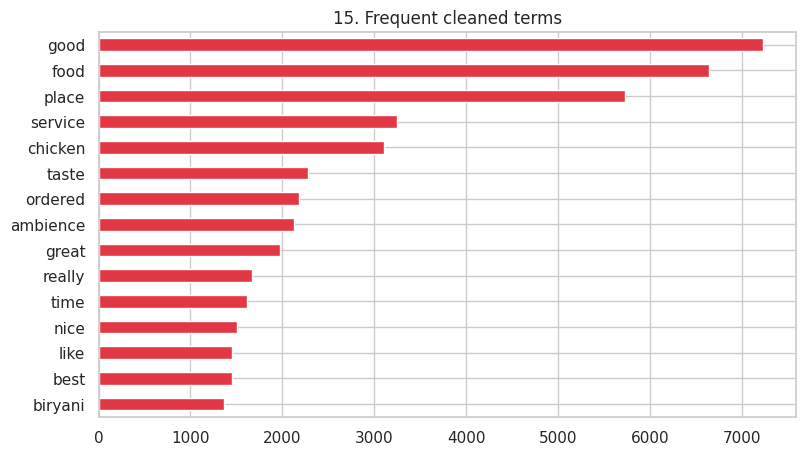

In [4]:
sns.set_theme(style="whitegrid")
RED,GOLD,GREEN,DARK="#E23744","#F4B942","#2E8B57","#333333"
# 1–15: univariate, bivariate and multivariate EDA
fig,ax=plt.subplots(figsize=(8,4)); model_df.Rating_num.value_counts().sort_index().plot.bar(color=RED,ax=ax); ax.set(title="1. Rating distribution",ylabel="Review count"); plt.show()
fig,ax=plt.subplots(figsize=(8,4)); model_df.sentiment.value_counts().reindex(["Negative","Neutral","Positive"]).plot.bar(color=[RED,GOLD,GREEN],ax=ax); ax.set(title="2. Sentiment class balance",ylabel="Review count"); plt.show()
fig,ax=plt.subplots(figsize=(8,4)); sns.histplot(model_df.word_count.clip(upper=model_df.word_count.quantile(.99)),bins=35,color=RED,ax=ax); ax.set(title="3. Review word count (99th percentile cap)"); plt.show()
fig,ax=plt.subplots(figsize=(8,4)); sns.histplot(model_df.Pictures.fillna(0).clip(upper=10),bins=np.arange(-.5,11.5,1),color=GOLD,ax=ax); ax.set(title="4. Picture count (capped at 10)"); plt.show()
fig,ax=plt.subplots(figsize=(9,5)); model_df.Restaurant.value_counts().head(12).sort_values().plot.barh(color=RED,ax=ax); ax.set(title="5. Most reviewed restaurants"); plt.show()
fig,ax=plt.subplots(figsize=(9,5)); ra=model_df.groupby("Restaurant").Rating_num.agg(["mean","count"]); ra[ra["count"]>=20].sort_values("mean").tail(12)["mean"].plot.barh(color=GREEN,ax=ax); ax.set(title="6. Highest mean ratings (20+ reviews)"); plt.show()
fig,ax=plt.subplots(figsize=(7,4)); model_df.assign(status=np.where(model_df.has_picture==1,"Has picture","No picture")).groupby("status").Rating_num.mean().reindex(["No picture","Has picture"]).plot.bar(color=[DARK,GOLD],ax=ax); ax.set(title="7. Mean rating by picture presence"); plt.show()
fig,ax=plt.subplots(figsize=(7,4)); pd.crosstab(model_df.has_picture,model_df.sentiment,normalize="index").reindex(columns=["Negative","Neutral","Positive"]).plot.bar(stacked=True,color=[RED,GOLD,GREEN],ax=ax); ax.set(title="8. Sentiment by picture presence"); plt.show()
fig,ax=plt.subplots(figsize=(8,4)); sns.histplot(meta.Cost_num.dropna(),bins=20,color=RED,ax=ax); ax.set(title="9. Restaurant listed cost distribution"); plt.show()
fig,ax=plt.subplots(figsize=(9,5)); meta.Cuisines.dropna().str.split(",").explode().str.strip().value_counts().head(15).sort_values().plot.barh(color=GOLD,ax=ax); ax.set(title="10. Most listed cuisines"); plt.show()
fig,ax=plt.subplots(figsize=(8,4)); sns.boxplot(data=model_df,x="sentiment",y="word_count",order=["Negative","Neutral","Positive"],showfliers=False,palette=[RED,GOLD,GREEN],ax=ax); ax.set(title="11. Word count by sentiment"); plt.show()
fig,ax=plt.subplots(figsize=(8,4)); sns.boxplot(data=model_df,x="Rating_num",y="word_count",showfliers=False,color=GOLD,ax=ax); ax.set(title="12. Word count by rating"); plt.show()
fig,ax=plt.subplots(figsize=(9,4)); model_df.dropna(subset=["Time_parsed"]).set_index("Time_parsed").resample("MS").size().plot(marker="o",color=RED,ax=ax); ax.set(title="13. Monthly review volume"); plt.show()
fig,ax=plt.subplots(figsize=(8,6)); sns.heatmap(model_df[["Rating_num","Pictures","review_length","word_count","has_picture"]].corr(),annot=True,cmap="coolwarm",center=0,fmt=".2f",ax=ax); ax.set(title="14. Correlation heatmap"); plt.show()
fig,ax=plt.subplots(figsize=(9,5)); v=CountVectorizer(stop_words="english",max_features=18); mat=v.fit_transform(model_df.review_clean); pd.Series(np.asarray(mat.sum(axis=0)).ravel(),index=v.get_feature_names_out()).nlargest(15).sort_values().plot.barh(color=RED,ax=ax); ax.set(title="15. Frequent cleaned terms"); plt.show()

### Chart 1 — Rating distribution
**Why this chart?** A bar chart compares each numeric rating and reveals the overall rating profile.

**Insight:** The distribution is concentrated in higher ratings, with a meaningful low-rating segment visible in the data.

**Business impact:** The profile establishes a satisfaction baseline; low-rating reviews should remain visible despite the positive majority.

### Chart 2 — Sentiment balance
**Why this chart?** A bar chart checks the size of each rating-derived class before modelling.

**Insight:** Positive is the largest class; neutral and negative are smaller, so class imbalance matters.

**Business impact:** Macro metrics and stratified splitting reduce the chance of overstating performance on the majority class.

### Chart 3 — Review length
**Why this chart?** A histogram shows the distribution of word counts; the 99th percentile cap is visual only.

**Insight:** Most reviews are shorter than the long-tail reviews.

**Business impact:** Short text needs robust features; detailed long reviews can be prioritized for qualitative reading.

### Chart 4 — Picture counts
**Why this chart?** A histogram shows picture uploads per review, capped at 10 for readability.

**Insight:** The distribution is heavily concentrated at zero, with relatively few multi-picture reviews.

**Business impact:** Pictures add context but should not replace text and rating analysis.

### Chart 5 — Review volume by restaurant
**Why this chart?** A horizontal bar chart identifies restaurants with the largest review counts.

**Insight:** The top restaurants have more observations and greater visibility in this sample.

**Business impact:** Volume can guide monitoring effort but does not equal restaurant quality.

### Chart 6 — Average restaurant ratings
**Why this chart?** A horizontal bar chart ranks mean ratings among restaurants with at least 20 reviews.

**Insight:** The minimum count reduces instability from very small samples.

**Business impact:** This is a benchmarking lead, not a definitive ranking or causal assessment.

### Chart 7 — Rating by picture presence
**Why this chart?** A bar chart compares mean rating for reviews with and without pictures.

**Insight:** Group means show the descriptive rating difference between picture groups.

**Business impact:** The result motivates investigation but cannot establish that pictures cause ratings to change.

### Chart 8 — Sentiment by picture presence
**Why this chart?** A stacked bar chart compares sentiment proportions across picture groups.

**Insight:** It reveals whether the sentiment mix differs by picture presence.

**Business impact:** Potential changes in negative share can guide human review workflows.

### Chart 9 — Cost distribution
**Why this chart?** A histogram summarizes numeric restaurant cost values from metadata.

**Insight:** It displays the spread and skew of the listed cost field.

**Business impact:** Cost segmentation can support positioning; currency and per-person basis are not specified in the source.

### Chart 10 — Cuisine frequency
**Why this chart?** A horizontal bar chart counts cuisine tags across restaurant metadata.

**Insight:** It identifies the most commonly listed cuisine categories in this sample.

**Business impact:** Useful for supply-side category context; demand data is needed for market conclusions.

### Chart 11 — Review length by sentiment
**Why this chart?** Boxplots compare word counts across sentiment categories.

**Insight:** Differences in medians and spread indicate how review length varies across rating groups.

**Business impact:** Longer negative reviews may contain more actionable detail; length is not a severity score.

### Chart 12 — Review length by rating
**Why this chart?** Boxplots compare review length at each rating level.

**Insight:** The chart reveals whether extreme ratings coincide with longer comments.

**Business impact:** Can help identify detailed low-rating feedback for human investigation.

### Chart 13 — Monthly review volume
**Why this chart?** A time-series chart counts reviews by month using parseable timestamps.

**Insight:** It reveals activity variation across the observed period.

**Business impact:** Useful for trend monitoring, while noting the dataset's collection window and timestamp gaps.

### Chart 14 — Correlation heatmap
**Why this chart?** A heatmap summarizes numeric correlations among rating, pictures, length and word count.

**Insight:** It highlights linear associations, not causal relationships.

**Business impact:** Can inform feature understanding and identify redundant measures.

### Chart 15 — Frequent terms
**Why this chart?** A horizontal bar chart counts common cleaned review tokens.

**Insight:** It surfaces recurring vocabulary but frequent words are not necessarily sentiment-specific.

**Business impact:** Can guide qualitative theme exploration and search taxonomy.

## 4. Hypothesis testing

**H1:** H0: rating distributions are equal for reviews with and without pictures. H1: they differ.  
**Test:** two-sided Mann–Whitney U, appropriate for two independent groups without a normality assumption.  
**Observed p-value:** 0.00211071. **Decision at 0.05:** Reject H0.

In [5]:
no_pic=model_df.loc[model_df.has_picture==0,"Rating_num"]
with_pic=model_df.loc[model_df.has_picture==1,"Rating_num"]
stat,p=mannwhitneyu(no_pic,with_pic,alternative="two-sided")
print("Mann–Whitney U:",stat,"p-value:",p)

Mann–Whitney U: 7547988.0 p-value: 0.0021107146301571566


**H2:** H0: picture presence and rating-derived sentiment are independent. H1: they are associated.  
**Test:** chi-square test of independence on a 2 × 3 contingency table.  
**Observed p-value:** 6.35685e-58. **Decision at 0.05:** Reject H0.

In [6]:
tab=pd.crosstab(model_df.has_picture,model_df.sentiment)
chi2,p,dof,expected=chi2_contingency(tab)
display(tab); print("Chi-square:",chi2,"dof:",dof,"p-value:",p)

sentiment,Negative,Neutral,Positive
has_picture,,,
0,2215,889,4849
1,210,319,1454


Chi-square: 263.4008053684499 dof: 2 p-value: 6.356848333168677e-58


**H3:** H0: rating distributions are equal across restaurants with at least 20 usable reviews. H1: at least one differs.  
**Test:** Kruskal–Wallis H, a non-parametric multi-group comparison.  
**Observed p-value:** 4.6991e-195. **Decision at 0.05:** Reject H0.

In [7]:
samples=[g.Rating_num.values for _,g in model_df.groupby("Restaurant") if len(g)>=20]
stat,p=kruskal(*samples)
print("Kruskal-Wallis H:",stat,"p-value:",p,"groups:",len(samples))

Kruskal-Wallis H: 1232.9740751587242 p-value: 4.699097934176156e-195 groups: 100


## 5. Feature engineering and preprocessing
**Missing values:** missing/non-numeric ratings are not imputed because they define the target. Missing review text becomes empty and empty cleaned text is excluded from supervised learning. Missing picture counts are treated as zero only for the picture-presence indicator. Missing metadata remains missing.

**Outliers:** review length and picture counts are right-tailed. Capping is used for selected chart displays only; original records are retained for training.

**Categorical encoding:** sentiment is the target class. TF-IDF encodes review text. Reviewer and restaurant identifiers are excluded as predictors to reduce identity leakage.

**Text preprocessing:** lowercase, URL removal, digit-containing token removal, punctuation removal and whitespace normalization. TF-IDF applies English stop-word filtering and unigram/bigram features. Lemmatization and POS tagging are not applied to avoid unnecessary transformation of negation/domain terms.

**Feature selection/manipulation:** `min_df=2`, `max_df=0.98`, and `max_features=30000` limit rare/common vocabulary and feature count. Vectorization is fitted inside each training fold.

**Scaling/dimensionality reduction:** TF-IDF uses L2 normalization. PCA is not used because sparse high-dimensional text is directly suited to linear classifiers.

**Split/imbalance:** stratified 80:20 split; class weights for Logistic Regression and Linear SVM; macro-F1 used for model selection.

## 6. ML model implementation

In [8]:
X=model_df.review_clean; y=model_df.sentiment
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=.2,random_state=42,stratify=y)
cv=StratifiedKFold(n_splits=3,shuffle=True,random_state=42)
def make_pipe(clf):
    return Pipeline([("tfidf",TfidfVectorizer(ngram_range=(1,2),min_df=2,max_df=.98,max_features=30000,
                      sublinear_tf=True,strip_accents="unicode",stop_words="english")),("clf",clf)])
specs=[
("Logistic Regression",make_pipe(LogisticRegression(max_iter=1200,class_weight="balanced",random_state=42)),{"clf__C":[.5,1,2]}),
("Linear SVM",make_pipe(LinearSVC(class_weight="balanced",random_state=42)),{"clf__C":[.5,1,2]}),
("Multinomial Naive Bayes",make_pipe(MultinomialNB()),{"clf__alpha":[.3,.7,1]})]
results=[]
for name,model,grid in specs:
    gs=GridSearchCV(model,grid,scoring="f1_macro",cv=cv,n_jobs=-1,refit=True)
    gs.fit(X_train,y_train); pred=gs.predict(X_test)
    results.append({"name":name,"search":gs,"model":gs.best_estimator_,"params":gs.best_params_,
      "cv_f1":gs.best_score_,"accuracy":accuracy_score(y_test,pred),
      "precision":precision_score(y_test,pred,average="macro",zero_division=0),
      "recall":recall_score(y_test,pred,average="macro",zero_division=0),
      "f1":f1_score(y_test,pred,average="macro",zero_division=0),"pred":pred})
metric_table=pd.DataFrame([{k:v for k,v in r.items() if k in ["name","params","cv_f1","accuracy","precision","recall","f1"]} for r in results])
display(metric_table)
best=max(results,key=lambda r:r["f1"]); best_model=best["model"]; best_pred=best["pred"]
print("Selected:",best["name"]); print(classification_report(y_test,best_pred,zero_division=0))

,name,params,cv_f1,accuracy,precision,recall,f1
0,Logistic Regression,{'clf__C': 2},0.689378,0.809356,0.697985,0.706722,0.701953
1,Linear SVM,{'clf__C': 0.5},0.679770,0.821429,0.698745,0.673730,0.682038
2,Multinomial Naive Bayes,{'clf__alpha': 0.3},0.558249,0.800302,0.547872,0.566059,0.550742


Selected: Logistic Regression
              precision    recall  f1-score   support

    Negative       0.80      0.80      0.80       485
     Neutral       0.39      0.43      0.41       242
    Positive       0.91      0.88      0.89      1261

    accuracy                           0.81      1988
   macro avg       0.70      0.71      0.70      1988
weighted avg       0.82      0.81      0.81      1988



### ML Model 1 — Logistic Regression
**Model:** Regularized linear classifier with class coefficients.  
**Best parameters:** `{'clf__C': 2}`  
**Cross-validation macro-F1:** 0.6894  
**Held-out accuracy:** 0.8094 | **Macro precision:** 0.6980 | **Macro recall:** 0.7067 | **Macro-F1:** 0.7020  
**Tuning:** stratified 3-fold GridSearchCV; best parameters selected on training folds.  
**Business interpretation:** precision measures reliability of predicted classes; recall measures coverage of actual classes; F1 balances both; accuracy is overall correctness. Macro averaging gives each class equal weight.

### ML Model 2 — Linear SVM
**Model:** Linear margin classifier suitable for sparse text features.  
**Best parameters:** `{'clf__C': 0.5}`  
**Cross-validation macro-F1:** 0.6798  
**Held-out accuracy:** 0.8214 | **Macro precision:** 0.6987 | **Macro recall:** 0.6737 | **Macro-F1:** 0.6820  
**Tuning:** stratified 3-fold GridSearchCV; best parameters selected on training folds.  
**Business interpretation:** precision measures reliability of predicted classes; recall measures coverage of actual classes; F1 balances both; accuracy is overall correctness. Macro averaging gives each class equal weight.

### ML Model 3 — Multinomial Naive Bayes
**Model:** Probabilistic token-frequency baseline.  
**Best parameters:** `{'clf__alpha': 0.3}`  
**Cross-validation macro-F1:** 0.5582  
**Held-out accuracy:** 0.8003 | **Macro precision:** 0.5479 | **Macro recall:** 0.5661 | **Macro-F1:** 0.5507  
**Tuning:** stratified 3-fold GridSearchCV; best parameters selected on training folds.  
**Business interpretation:** precision measures reliability of predicted classes; recall measures coverage of actual classes; F1 balances both; accuracy is overall correctness. Macro averaging gives each class equal weight.

### Model evaluation charts and feature interpretation

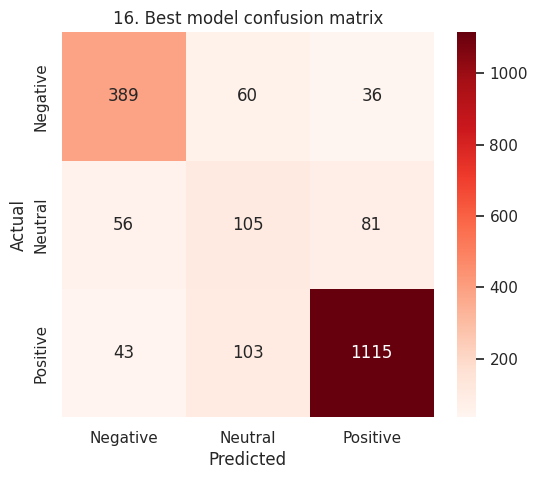

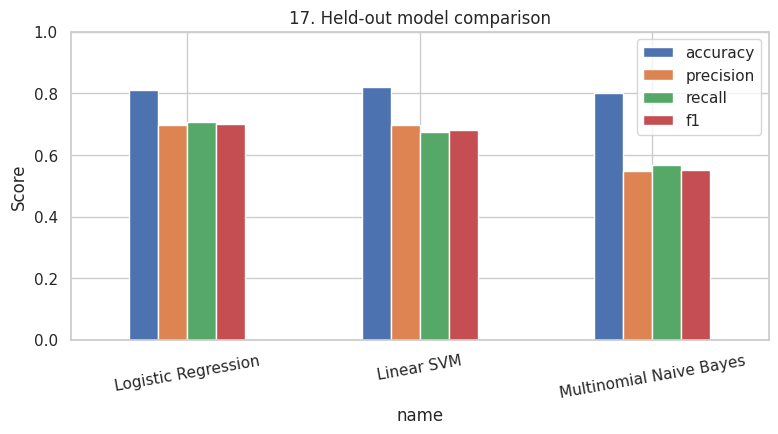

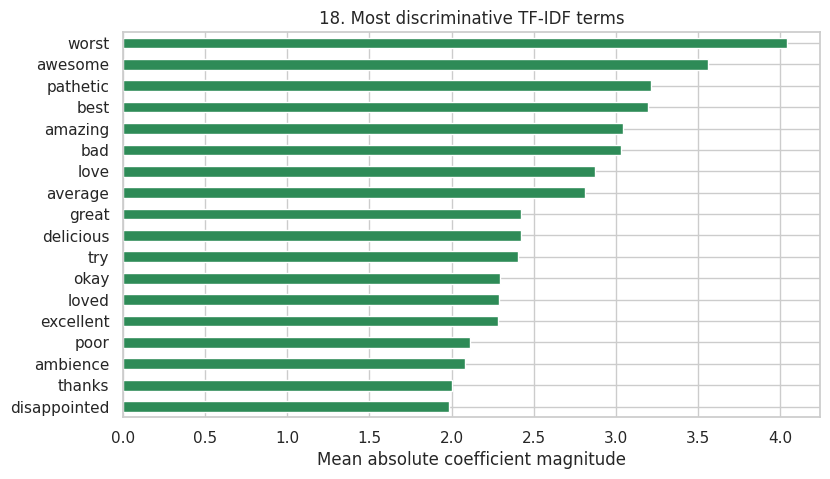

In [9]:
plt.figure(figsize=(6,5))
sns.heatmap(confusion_matrix(y_test,best_pred,labels=["Negative","Neutral","Positive"]),annot=True,fmt="d",cmap="Reds",
            xticklabels=["Negative","Neutral","Positive"],yticklabels=["Negative","Neutral","Positive"])
plt.xlabel("Predicted"); plt.ylabel("Actual"); plt.title("16. Best model confusion matrix"); plt.show()
metric_table.set_index("name")[["accuracy","precision","recall","f1"]].plot.bar(figsize=(9,4),ylim=(0,1),rot=10)
plt.title("17. Held-out model comparison"); plt.ylabel("Score"); plt.show()
clf=best_model.named_steps["clf"]
if hasattr(clf,"coef_"):
    vocab=np.array(best_model.named_steps["tfidf"].get_feature_names_out())
    importance=np.mean(np.abs(clf.coef_),axis=0); top=np.argsort(importance)[-18:]
    pd.Series(importance[top],index=vocab[top]).sort_values().plot.barh(figsize=(9,5),color="#2E8B57")
    plt.title("18. Most discriminative TF-IDF terms"); plt.xlabel("Mean absolute coefficient magnitude"); plt.show()

### Final model selection
**Selected model:** Logistic Regression because it achieved the highest held-out macro-F1 (0.7020). Macro-F1 is prioritized over accuracy because sentiment classes are imbalanced. The confusion matrix should be reviewed for missed negative reviews and false alarms. Coefficients are model associations, not causal explanations.

## 7. Save model and predict unseen reviews

In [10]:
joblib.dump(best_model,"zomato_sentiment_model.joblib")
loaded=joblib.load("zomato_sentiment_model.joblib")
unseen=["The food was delicious and staff were very friendly",
        "The order arrived cold and service was extremely slow",
        "The restaurant was okay, nothing special"]
pred=loaded.predict([clean_review(t) for t in unseen])
display(pd.DataFrame({"review":unseen,"predicted_sentiment":pred}))

,review,predicted_sentiment
0,The food was delicious and staff were very fri...,Positive
1,The order arrived cold and service was extreme...,Negative
2,"The restaurant was okay, nothing special",Neutral


## 8. Conclusion and future work
This project analysed 10,000 review rows and 105 restaurant metadata rows. 9,936 records were suitable for supervised learning after transparent target and text validation. Three TF-IDF classifiers were tuned and compared. The selected model, Logistic Regression, achieved held-out accuracy 0.8094 and macro-F1 0.7020. These metrics describe reproduction of rating-derived labels and should not be mistaken for independent sentiment accuracy.

Business use: triage potentially negative reviews for human inspection, monitor restaurant feedback and investigate recurring complaint language. Future work should collect human-labelled sentiment, run time-based external validation, add multilingual support, calibrate confidence, monitor drift and deploy a monitored API. Replace `[Your Name]`, add GitHub URL and execute all cells from a clean kernel before submission.